# 2. N-gram baselines and the terminator experiment

The oldest language model is the **n-gram**: predict the next codon from the previous $n-1$ codons and nothing
else (the Markov assumption, as in Zombienella 02b):

$$P(w_t \mid w_1,\ldots,w_{t-1}) \approx P(w_t \mid w_{t-n+1},\ldots,w_{t-1}).$$

This notebook trains n-grams of orders 1–4 on the transcripts and runs the experiment the Protocell-0 spec was
built around (protocell-0-spec §4.1):

> At a gene's last position, which **terminator** comes next? Each of the seven Nax genes has its own. The answer
> is written in the gene's **marker**, 12–24 codons earlier — out of reach of any n-gram with $n \le 4$.

An n-gram can still guess better than chance, because the **dialect** of the last few body codons hints at the
gene. The encoders of notebook 04b can reach back to the marker. The prediction, fixed in design-spec §7 before
running (P6):

- (a) every n-gram of order 2–4 beats chance (1/7) on the terminator;
- (b) the `causal` encoder — which, like an n-gram, sees only the left context — beats the best n-gram by at
  least 0.10.

*Run from `02-ngrams/`, after notebooks 01 and 04b.*

In [1]:
import sys, json, math
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
import protocell_lang as L

SEED = 42
ORDERS = [1, 2, 3, 4]
K = 0.1                         # add-k smoothing, fixed in advance (design-spec §6, Phase 6)
CONFIGS = ["full", "no_position", "causal"]
CORPUS_DIR = "../data/corpus"
WEB_DIR = "../data/web"

TERMINATORS = {L.transcribe(g["terminator"]): g["name"] for g in L.GENES}     # RNA spelling
MARKERS = {L.transcribe(g["marker"]): g["name"] for g in L.GENES}

## 1. Data: the same split as the encoder

The n-grams learn from the transcripts of the encoder's **training** genomes (read from the exported encoder file),
and are tested on the same 150 unique test transcripts as notebook 04c — one per (genome, condition). Each
sequence is wrapped in `<s>` … `</s>` so the model also learns how transcripts start and end.

In [2]:
with open(f"{WEB_DIR}/encoder-full.json") as f:
    encoder_config = json.load(f)["config"]
train_genomes, test_genomes = set(encoder_config["train_genomes"]), set(encoder_config["test_genomes"])

frame = pd.read_csv(f"{CORPUS_DIR}/transcripts.csv").sort_values(["transcript_id", "position"])
by_transcript = {tid: g for tid, g in frame.groupby("transcript_id")}
train = [g["codon"].tolist() for g in by_transcript.values() if g["genome_id"].iloc[0] in train_genomes]

test_frame = frame[frame["genome_id"].isin(test_genomes)]
first = test_frame.groupby(["genome_id", "condition"])["transcript_id"].min()
test = [{"tokens": by_transcript[tid]["codon"].tolist(), "region": by_transcript[tid]["region"].tolist(),
         "gene": by_transcript[tid]["gene"].tolist(), "condition": cond} for (gid, cond), tid in first.items()]

VOCABULARY = [L.transcribe(c) for c in L.ALL_CODONS] + ["</s>"]       # what an n-gram can predict
print(f"{len(train)} training transcripts, {len(test)} test transcripts, {len(VOCABULARY)} predictable symbols")

1280 training transcripts, 150 test transcripts, 65 predictable symbols


## 2. Counting n-grams

For order $n$, every position of a padded sequence gives one (context, next token) pair, where the context is the
previous $n-1$ tokens. Probabilities use **add-k smoothing** so that unseen continuations are not impossible:

$$P(w \mid c) = \frac{C(c, w) + k}{C(c) + k\,|V|}, \qquad k = 0.1.$$

In [3]:
def extract_ngrams(tokens, n):
    padded = ["<s>"] * (n - 1) + tokens + ["</s>"]
    return [(tuple(padded[i - n + 1:i]), padded[i]) for i in range(n - 1, len(padded))]


class NGramModel:
    def __init__(self, n, k=K):
        self.n, self.k = n, k
        self.counts = defaultdict(Counter)       # context -> Counter of next tokens
        self.totals = Counter()                  # context -> number of times it was seen

    def fit(self, sequences):
        for tokens in sequences:
            for context, token in extract_ngrams(tokens, self.n):
                self.counts[context][token] += 1
                self.totals[context] += 1
        return self

    def prob(self, history, token):
        context = tuple((["<s>"] * (self.n - 1) + list(history))[-(self.n - 1):]) if self.n > 1 else ()
        return (self.counts[context][token] + self.k) / (self.totals[context] + self.k * len(VOCABULARY))


models = {n: NGramModel(n).fit(train) for n in ORDERS}
for n in ORDERS:
    print(f"order {n}: {len(models[n].counts):6,} distinct contexts")

# Sanity check: probabilities over the vocabulary sum to 1 for any context, seen or not.
for n in ORDERS:
    for history in (train[0][:5], ["XXX", "YYY", "VVV"]):
        assert abs(sum(models[n].prob(history, w) for w in VOCABULARY) - 1) < 1e-9

top = Counter({(" ".join(c) + " → " + w): models[3].counts[c][w] for c in models[3].counts for w in models[3].counts[c]})
pd.DataFrame(top.most_common(8), columns=["3-gram (context → next)", "count"])

order 1:      1 distinct contexts
order 2:     65 distinct contexts
order 3:  2,939 distinct contexts
order 4: 13,527 distinct contexts


,3-gram (context → next),count
0,WYW WVV → VVV,1289
1,WYW YWV → WYW,1280
2,YWV WYW → WVV,1280
3,WVV VVV → </s>,1280
4,XWY XWY → XWY,436
5,<s> <s> → WXX,368
6,VWW WXX → WXX,365
7,VWX WYW → YWV,352


## 3. How good are the n-grams as language models?

**Cross-entropy** is the average number of bits the model needs per codon of an unseen transcript (lower is
better); **perplexity** $= 2^{\text{cross-entropy}}$ is the effective number of codons it hesitates between. A
model that knew nothing would need $\log_2 65 \approx 6.0$ bits (perplexity 65). This is the same quantity as the
"bits per monomer" of Kurisu et al. (protocell-0-spec §6).

In [4]:
def cross_entropy(model, sequences):
    bits = count = 0
    for tokens in sequences:
        for i, token in enumerate(tokens + ["</s>"]):
            bits -= math.log2(model.prob(tokens[:i], token))
            count += 1
    return bits / count


test_tokens = [t["tokens"] for t in test]
quality = pd.DataFrame([{"order": n, "test cross-entropy (bits/codon)": cross_entropy(models[n], test_tokens),
                         "training cross-entropy (training performance)": cross_entropy(models[n], train[:150])}
                        for n in ORDERS])
quality["test perplexity"] = 2 ** quality["test cross-entropy (bits/codon)"]
quality.round(3)

,order,test cross-entropy (bits/codon),training cross-entropy (training performance),test perplexity
0,1,5.094,5.071,34.152
1,2,4.162,4.007,17.907
2,3,4.097,3.360,17.115
3,4,5.079,2.604,33.804


### A transcript written by the 4-gram

Sampling one codon at a time from the 4-gram gives text that looks right locally. The check below asks whether
each gene marker it writes is followed by **its own** terminator — the long-range rule an n-gram cannot see.

In [5]:
def generate(model, rng, max_length=250):
    tokens = []
    while len(tokens) < max_length:
        weights = np.array([model.prob(tokens, w) for w in VOCABULARY])
        token = VOCABULARY[rng.choice(len(VOCABULARY), p=weights / weights.sum())]
        if token == "</s>":
            break
        tokens.append(token)
    return tokens


rng = np.random.default_rng(SEED)
pairs = []
for _ in range(20):
    tokens = generate(models[4], rng)
    for i, token in enumerate(tokens):
        if token in MARKERS:
            following = next((t for t in tokens[i + 1:] if t in TERMINATORS), None)
            if following:
                pairs.append(MARKERS[token] == TERMINATORS[following])
sample = generate(models[4], np.random.default_rng(SEED + 1))
print("one sample:", " ".join(f"[{t}]" if t in MARKERS or t in TERMINATORS else t for t in sample[:60]), "…")
print(f"\nIn 20 generated transcripts: {len(pairs)} marker → next terminator pairs, {np.mean(pairs):.2f} of them matching "
      f"(chance ≈ {1 / 7:.2f}; real transcripts: 1.00)")

one sample: XVV WXX WXX YVV YXX XXV [VWW] XWX XYV XVX VVY VYX XWY XWY XYV WWW XXW VVX VXY YWY XVV VVX YXY VVX …

In 20 generated transcripts: 129 marker → next terminator pairs, 0.12 of them matching (chance ≈ 0.14; real transcripts: 1.00)


## 4. The terminator experiment

One item per gene terminator in the 150 test transcripts (`K_high` transcripts only contain NaxGATE and NaxTAG).
At that position each model ranks the **seven terminator codons** and picks the most probable one; chance is 1/7.

- **n-grams** use $P(t \mid \text{previous } n-1 \text{ codons})$ — after 12–24 body codons, that context holds
  only body codons, i.e. dialect.
- **encoders** see the whole transcript with the terminator replaced by `[MASK]` and read their masked-token head.

In [6]:
items = []
for t, tr in enumerate(test):
    for i, (token, region) in enumerate(zip(tr["tokens"], tr["region"])):
        if region == "terminator":
            items.append({"transcript": t, "position": i, "truth": token, "gene": tr["gene"][i]})
assert len(items) == sum(r == "terminator" for tr in test for r in tr["region"])
truth = np.array([it["truth"] for it in items])
majority = Counter(truth).most_common(1)[0][1] / len(truth)
print(f"{len(items)} terminator items · chance {1 / 7:.3f} · always guessing the most frequent terminator {majority:.3f}")

predictions = {}
for n in ORDERS:
    predictions[f"{n}-gram"] = np.array([max(TERMINATORS, key=lambda c: models[n].prob(test[it["transcript"]]["tokens"][:it["position"]], c))
                                         for it in items])

655 terminator items · chance 0.143 · always guessing the most frequent terminator 0.229


### The encoders, run from their exported weights

As in notebook 04c, a NumPy forward pass reads the JSON weights of 04b (the files Lab C uses) and is first checked
against PyTorch's parity values.

In [7]:
def layer_norm(x, gamma, beta, eps):
    mean = x.mean(axis=-1, keepdims=True)
    variance = ((x - mean) ** 2).mean(axis=-1, keepdims=True)
    return (x - mean) / np.sqrt(variance + eps) * gamma + beta


def encoder_forward(W, config, ids):
    n, d, heads = len(ids), config["d_model"], config["n_heads"]
    d_head, eps = d // heads, config["layer_norm_eps"]
    x = W["tok_emb.weight"][ids] + (W["pos_emb.weight"][:n] if config["use_position"] else 0)
    for layer in range(config["n_layers"]):
        p = f"blocks.{layer}."
        a = layer_norm(x, W[p + "ln1.weight"], W[p + "ln1.bias"], eps)
        q, k, v = np.split(a @ W[p + "attn.qkv.weight"].T + W[p + "attn.qkv.bias"], 3, axis=-1)
        q, k, v = (t.reshape(n, heads, d_head).transpose(1, 0, 2) for t in (q, k, v))
        scores = q @ k.transpose(0, 2, 1) / np.sqrt(d_head)
        if config["causal"]:
            scores = np.where(np.tril(np.ones((n, n), dtype=bool)), scores, -np.inf)
        weights = np.exp(scores - scores.max(axis=-1, keepdims=True))
        weights /= weights.sum(axis=-1, keepdims=True)
        x = x + (weights @ v).transpose(1, 0, 2).reshape(n, d) @ W[p + "attn.out.weight"].T + W[p + "attn.out.bias"]
        hidden = np.maximum(0, layer_norm(x, W[p + "ln2.weight"], W[p + "ln2.bias"], eps) @ W[p + "ff1.weight"].T + W[p + "ff1.bias"])
        x = x + hidden @ W[p + "ff2.weight"].T + W[p + "ff2.bias"]
    final = layer_norm(x, W["ln_final.weight"], W["ln_final.bias"], eps)
    return final, final @ W["head.weight"].T + W["head.bias"]


with open(f"{WEB_DIR}/parity-tests.json") as f:
    parity = json.load(f)
encoders = {}
for name in CONFIGS:
    with open(f"{WEB_DIR}/encoder-{name}.json") as f:
        data = json.load(f)
    encoders[name] = (data["config"], {k: np.array(v) for k, v in data["snapshots"][-1]["weights"].items()})
    worst = max(np.abs(encoder_forward(encoders[name][1], encoders[name][0], test_case["ids"])[0] - test_case["final"]).max()
                for test_case in parity["configs"][name]["tests"])
    print(f"{name:12} NumPy vs PyTorch parity: max |Δ| = {worst:.1e}")
    assert worst <= parity["tolerance"]

full         NumPy vs PyTorch parity: max |Δ| = 5.0e-08
no_position  NumPy vs PyTorch parity: max |Δ| = 5.0e-08
causal       NumPy vs PyTorch parity: max |Δ| = 5.0e-08


In [8]:
def encoder_terminator(name, it):
    config, W = encoders[name]
    vocab = config["vocabulary"]
    tokens = test[it["transcript"]]["tokens"]
    ids = [vocab.index("[CLS]")] + [vocab.index(t) for t in tokens] + [vocab.index("[EOS]")]
    ids[it["position"] + 1] = vocab.index("[MASK]")
    logits = encoder_forward(W, config, ids)[1][it["position"] + 1]
    return max(TERMINATORS, key=lambda c: logits[vocab.index(c)])


for name in CONFIGS:
    predictions[f"encoder {name}"] = np.array([encoder_terminator(name, it) for it in items])

## 5. Results

,items,overall,NaxGATE,NaxTAG,NaxSNIP,NaxFLIP,NaxGRAB,NaxPAY,NaxDUMP
1-gram,655,0.229,1.000,0.000,0.000,0.000,0.000,0.000,0.000
2-gram,655,0.484,0.707,0.620,0.239,0.296,0.465,0.268,0.394
3-gram,655,0.573,0.720,0.660,0.549,0.465,0.521,0.465,0.366
4-gram,655,0.490,0.960,0.307,0.451,0.338,0.380,0.296,0.380
encoder full,655,0.916,0.987,0.987,0.859,0.845,0.845,0.873,0.859
encoder no_position,655,0.418,0.527,0.713,0.000,0.352,0.099,0.789,0.000
encoder causal,655,0.963,1.000,1.000,0.972,0.930,0.930,0.887,0.944


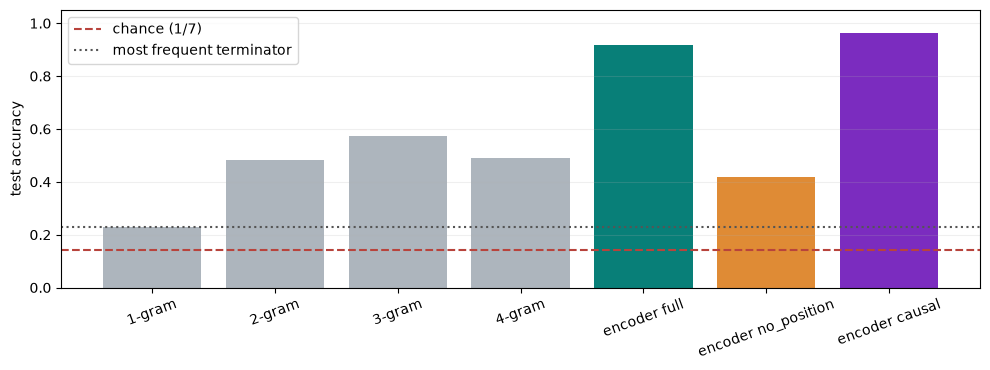

Note: the full encoder also sees the RIGHT context; in pathway order the next gene's RBS and marker reveal
the current gene, so its number is not a like-for-like comparison with the n-grams.


In [9]:
genes = np.array([it["gene"] for it in items])
accuracy = pd.DataFrame({model: {"overall": float(np.mean(pred == truth)),
                                 **{g: float(np.mean(pred[genes == g] == truth[genes == g])) for g in L.GENE_NAMES}}
                         for model, pred in predictions.items()}).T
accuracy.insert(0, "items", len(items))
display(accuracy.round(3))

fig, ax = plt.subplots(figsize=(10, 3.8))
colours = ["#adb5bd"] * len(ORDERS) + ["#087f78", "#df8b35", "#7b2cbf"]
ax.bar(accuracy.index, accuracy["overall"], color=colours)
ax.axhline(1 / 7, color="#b8433c", ls="--", label="chance (1/7)")
ax.axhline(majority, color="#555", ls=":", label="most frequent terminator")
ax.set_ylabel("test accuracy")
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis="y", alpha=0.2)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()
print("Note: the full encoder also sees the RIGHT context; in pathway order the next gene's RBS and marker reveal\n"
      "the current gene, so its number is not a like-for-like comparison with the n-grams.")

### A check on ties

When an n-gram has never seen a context, add-k smoothing gives all seven terminators the same probability, and
"pick the highest" falls back on the first terminator in the list — NaxGATE's. That inflates NaxGATE and deflates
the rest. The table shows how often each order ties, and the accuracy it would get if ties were split evenly
(each of the seven counted as 1/7 correct). The pre-registered verdict below uses the rule as written; this is
reported so that the rule's side effect is visible.

In [10]:
tie_rows = []
for n in ORDERS:
    tied, expected = 0, 0.0
    for it, pred in zip(items, predictions[f"{n}-gram"]):
        history = test[it["transcript"]]["tokens"][:it["position"]]
        scores = [models[n].prob(history, c) for c in TERMINATORS]
        best = [c for c, s in zip(TERMINATORS, scores) if s == max(scores)]
        tied += len(best) > 1
        expected += (it["truth"] in best) / len(best)
    tie_rows.append({"order": n, "items with tied scores": tied, "share tied": tied / len(items),
                     "accuracy (rule as written)": float(np.mean(predictions[f"{n}-gram"] == truth)),
                     "accuracy if ties split evenly": expected / len(items)})
pd.DataFrame(tie_rows).round(3)

,order,items with tied scores,share tied,accuracy (rule as written),accuracy if ties split evenly
0,1,0,0.000,0.229,0.229
1,2,0,0.000,0.484,0.484
2,3,21,0.032,0.573,0.576
3,4,343,0.524,0.490,0.437


In [11]:
ngram_acc = {n: float(accuracy.loc[f"{n}-gram", "overall"]) for n in ORDERS}
causal_acc = float(accuracy.loc["encoder causal", "overall"])
best_ngram = max(ngram_acc[n] for n in (2, 3, 4))
p6a = all(ngram_acc[n] > 1 / 7 for n in (2, 3, 4))
p6b = causal_acc >= best_ngram + 0.10
print(f"P6(a) n-grams of order 2–4 beat chance (1/7 = {1 / 7:.3f}): {[round(ngram_acc[n], 3) for n in (2, 3, 4)]} → {'yes' if p6a else 'no'}")
print(f"P6(b) causal encoder {causal_acc:.3f} ≥ best n-gram {best_ngram:.3f} + 0.10 = {best_ngram + 0.10:.3f} → {'yes' if p6b else 'no'}")
print("P6", "HOLDS" if p6a and p6b else "FAILS")

P6(a) n-grams of order 2–4 beat chance (1/7 = 0.143): [0.484, 0.573, 0.49] → yes
P6(b) causal encoder 0.963 ≥ best n-gram 0.573 + 0.10 = 0.673 → yes
P6 HOLDS


### What came out (seed 42)

**P6 holds.** Both parts:
- **(a) Every n-gram of order 2–4 beats chance on the terminator:** 0.484, 0.573 and 0.490 against 1/7 = 0.143.
- **(b) The `causal` encoder beats the best n-gram by more than 0.10:** 0.963 against 0.573.

**What the n-grams can and cannot do.**
- The unigram always answers NaxGATE's terminator, the most frequent one (NaxGATE is in every transcript).
  It scores exactly the majority rate, 0.229.
- From order 2 on, the last body codons carry the gene's **dialect**, and accuracy more than doubles. This is
  the "dialect leakage" of protocell-0-spec §4.1: local word choice betrays the topic.
- No n-gram can see the marker, 12–24 codons back. The generated transcripts show what that costs: only 0.12 of
  their markers are followed by the matching terminator, which is chance level. The real grammar always
  matches.

**More context is not always better.**
- The 4-gram is worse than the 3-gram: test perplexity 33.8 against 17.1, and terminator accuracy 0.490 against
  0.573.
- With 13,527 contexts from 1,280 transcripts, most 4-gram contexts are seen once or never. The model memorises
  the training transcripts (training cross-entropy 2.60 bits) and generalises badly (5.08 bits on test). This is
  the classic **data sparsity** of n-grams, and the reason smoothing and, later, neural models were needed.
- Half of its terminator decisions are ties between never-seen contexts (the tie check above). If those ties
  were split evenly, it would score 0.437. That is still above chance, so the verdict does not depend on how
  ties are broken.

**The encoders.**
- **`causal` (0.963)** sees exactly what an n-gram sees — the left context — but all of it, back to the marker.
  The gap of 0.39 over the best n-gram is what that reach buys.
- **`full` (0.916)** also sees the right-hand context, which in pathway order reveals the gene through the next
  gene's RBS and marker. Even so, it is *below* `causal` here. Seeing more is not automatically better for a
  model trained on another objective.
- **`no_position` (0.418)** is below the 3-gram. Without positions it cannot tell *which* marker in the
  transcript belongs to the gene that is ending, so it is right mainly for NaxTAG and NaxPAY, and never for
  NaxSNIP or NaxDUMP.

**Training performance vs test.** The training cross-entropies (measured on 150 training transcripts) fall
steadily with the order, while the test cross-entropy rises again at order 4. A gap like this is the
signature of over-fitting.